
# MODEL 2: RNN (LSTM/GRU) on MediaPipe landmarks (CSV features)
 Uses the SAME CSV you used for Model 1 (SVM).

 #### Key idea:
 - Your 63 features can be treated as a sequence of 21 landmarks,
   each landmark has 3 values (x,y,z)  => (timesteps=21, features=3)
 - Then we can train an RNN (LSTM/GRU) for classification.

 #### Outputs:
 - model2_rnn_landmarks.keras
 - model2_confusion_matrix_rnn.png
 - model2_rnn_metrics.csv
 - model2_label_encoder.joblib


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models

### CONFIG (EDIT PATH)

In [17]:
DATA_PATH = r"asl_landmarks_final.csv"
RANDOM_STATE = 42
TEST_SIZE = 0.20

EPOCHS = 30
BATCH_SIZE = 64
RNN_TYPE = "LSTM"  # "LSTM" or "GRU"

possible_label_cols = ["label", "Label", "class", "Class", "sign", "Sign", "gesture", "Gesture", "letter", "Letter"]

#### 1) LOAD DATASET

In [18]:
df = pd.read_csv(DATA_PATH)
print("Loaded dataset:", df.shape)
print(df.head())

Loaded dataset: (2203, 64)
         x0        y0            z0        x1        y1        z1        x2  \
0  0.302490  0.495331 -4.277665e-07  0.401974  0.430925 -0.032561  0.477837   
1  0.765451  0.343823 -3.595415e-07  0.847147  0.297660 -0.020126  0.900564   
2  0.354618  0.851986 -5.631421e-07  0.456605  0.802520 -0.032938  0.531164   
3  0.508807  0.903747 -4.856587e-07  0.601312  0.872814 -0.048935  0.698089   
4  0.424728  0.795478 -5.605922e-07  0.571597  0.744283 -0.063864  0.700230   

         y2        z2        x3  ...       x18       y18       z18       x19  \
0  0.337875 -0.043061  0.478437  ...  0.213375  0.267955 -0.066850  0.231382   
1  0.220337 -0.024878  0.908948  ...  0.702640  0.151641 -0.048588  0.717729   
2  0.713107 -0.044213  0.533721  ...  0.292963  0.614532 -0.061759  0.306808   
3  0.763118 -0.064034  0.720130  ...  0.421785  0.662791 -0.088294  0.430163   
4  0.593906 -0.080447  0.721148  ...  0.309938  0.437413 -0.105951  0.333689   

        y19      

#### 2) DETECT LABEL + FEATURE COLS

In [19]:
label_col = next((c for c in possible_label_cols if c in df.columns), None)
if label_col is None:
    raise ValueError(
        "Label column not found. Rename your label column to one of: "
        + ", ".join(possible_label_cols)
    )
print("Label column:", label_col)

feature_cols = [c for c in df.columns if c != label_col and pd.api.types.is_numeric_dtype(df[c])]
if len(feature_cols) < 63:
    raise ValueError(f"Expected at least 63 numeric features, found {len(feature_cols)}. Check your dataset columns.")

# Use only the first 63 numeric features (if you have extra engineered features)
feature_cols = feature_cols[:63]
print("Using numeric feature columns:", len(feature_cols))

X = df[feature_cols].to_numpy(dtype=np.float32)
y_raw = df[label_col].astype(str).to_numpy()

print("X shape (flat):", X.shape)

Label column: label
Using numeric feature columns: 63
X shape (flat): (2203, 63)


#### 3) LABEL ENCODING

In [20]:
le = LabelEncoder()
y = le.fit_transform(y_raw)
num_classes = len(le.classes_)
print("Classes:", list(le.classes_))
print("Num classes:", num_classes)

Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'space']
Num classes: 28


#### 4) TRAIN/TEST SPLIT (STRATIFIED)

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1762, 63) Test: (441, 63)


#### 5) STANDARDIZE FEATURES (fit on train only)

In [23]:
def preprocess_and_scale(X_train_flat, X_test_flat, scaler_path='model2_scaler.joblib'):
    # reshape flat (N,63) -> (N,21,3)
    if X_train_flat.shape[1] != 63:
        raise ValueError(f'Expected 63 features for reshaping, got {X_train_flat.shape[1]}')
    X_train_seq = X_train_flat.reshape(-1,21,3)
    X_test_seq = X_test_flat.reshape(-1,21,3)
    # center on wrist (assume landmark 0 is wrist) -> relative coords
    ref_train = X_train_seq[:,0:1,:]
    ref_test = X_test_seq[:,0:1,:]
    X_train_rel = X_train_seq - ref_train
    X_test_rel = X_test_seq - ref_test
    # compute deltas (velocity-like features)
    del_train = np.concatenate([np.zeros((X_train_rel.shape[0],1,3)), X_train_rel[:,1:,:]-X_train_rel[:,:-1,:]], axis=1)
    del_test = np.concatenate([np.zeros((X_test_rel.shape[0],1,3)), X_test_rel[:,1:,:]-X_test_rel[:,:-1,:]], axis=1)
    # concatenate coords + deltas -> (N,21,6)
    X_train_aug = np.concatenate([X_train_rel, del_train], axis=2)
    X_test_aug = np.concatenate([X_test_rel, del_test], axis=2)
    # fit scaler on flattened (per-sample) training augmented features
    N, T, F = X_train_aug.shape
    scaler = StandardScaler()
    X_train_flat_aug = X_train_aug.reshape(N, T*F)
    scaler.fit(X_train_flat_aug)
    X_train_scaled = scaler.transform(X_train_flat_aug).reshape(N, T, F)
    N2 = X_test_aug.shape[0]
    X_test_scaled = scaler.transform(X_test_aug.reshape(N2, T*F)).reshape(N2, T, F)
    joblib.dump(scaler, scaler_path)
    print(f"Saved scaler: {scaler_path}")
    return X_train_scaled, X_test_scaled

# Run preprocessing + scaling to get sequences for the RNN (shape: N,21,6)
X_train_seq, X_test_seq = preprocess_and_scale(X_train, X_test)
print("X_train_seq shape after preprocess+scale:", X_train_seq.shape)

Saved scaler: model2_scaler.joblib
X_train_seq shape after preprocess+scale: (1762, 21, 6)


#### 6) RESHAPE FOR RNN: (N, 63) -> (N, 21, 3)
 Assumption: 63 = 21 landmarks * 3 coords (x,y,z)

In [24]:
def to_sequence(x_flat: np.ndarray) -> np.ndarray:
    if x_flat.shape[1] != 63:
        raise ValueError(f"Expected 63 features for reshaping, got {x_flat.shape[1]}")
    return x_flat.reshape((-1, 21, 3))

# X_train_seq and X_test_seq are produced by preprocess_and_scale above (shape: N,21,6)
# If you need a pure reshape (no deltas), use to_sequence(X_train) etc.
print("X_train_seq shape (already preprocessed):", X_train_seq.shape)

X_train_seq shape (already preprocessed): (1762, 21, 6)


#### 7) BUILD RNN MODEL (LSTM/GRU)

In [25]:
tf.keras.backend.clear_session()

# Input now has 6 features per landmark (x,y,z + delta_x,delta_y,delta_z)
inputs = layers.Input(shape=(21, 6))

# Conv1D feature extractor
x = layers.Conv1D(64, kernel_size=3, padding='same', activation=None)(inputs)
x = layers.BatchNormalization()(x)
x = layers.Activation('relu')(x)
x = layers.Conv1D(64, kernel_size=3, padding='same', activation=None)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation('relu')(x)

# Bidirectional RNN stack
if RNN_TYPE.upper() == "GRU":
    x = layers.Bidirectional(layers.GRU(128, return_sequences=True, kernel_regularizer=tf.keras.regularizers.l2(1e-5)))(x)
    x = layers.Bidirectional(layers.GRU(64, return_sequences=False, kernel_regularizer=tf.keras.regularizers.l2(1e-5)))(x)
else:
    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True, kernel_regularizer=tf.keras.regularizers.l2(1e-5)))(x)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=False, kernel_regularizer=tf.keras.regularizers.l2(1e-5)))(x)

x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-5))(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(num_classes, activation='softmax')(x)

model2 = models.Model(inputs, outputs, name=f"model2_{RNN_TYPE.upper()}_improved")

model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model2.summary()

Model: "model2_LSTM_improved"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 21, 6)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 21, 64)         │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 21, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 21, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 21, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 21, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 21, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 21, 256)        │       197,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 28)             │         3,612 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 396,700 (1.51 MB)

 Trainable params: 396,188 (1.51 MB)

 Non-trainable params: 512 (2.00 KB)

#### 8) TRAIN

In [26]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint("model2_best.keras", monitor="val_accuracy", save_best_only=True),
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
]

# Optional: compute class weights if your dataset is imbalanced
# from sklearn.utils.class_weight import compute_class_weight
# class_weights = dict(zip(np.unique(y_train), compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)))

history = model2.fit(
    X_train_seq, y_train,
    validation_split=0.15,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    # class_weight=class_weights,  # enable if computed
    verbose=1,
 )

Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 11s 111ms/step - accuracy: 0.2104 - loss: 2.8449 - val_accuracy: 0.3736 - val_loss: 3.0715 - learning_rate: 0.0010
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.5377 - loss: 1.5376 - val_accuracy: 0.6151 - val_loss: 2.9043 - learning_rate: 0.0010
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.7301 - loss: 0.9635 - val_accuracy: 0.7094 - val_loss: 2.6439 - learning_rate: 0.0010
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - accuracy: 0.7936 - loss: 0.7178 - val_accuracy: 0.7358 - val_loss: 2.3663 - learning_rate: 0.0010
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - accuracy: 0.8370 - loss: 0.5605 - val_accuracy: 0.8000 - val_loss: 2.0554 - learning_rate: 0.0010
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - accuracy: 0.8671 - loss: 0.4483 - val_accuracy: 0.7811 - val_loss: 1.7504 - learning_rate: 0.0010
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accuracy: 0.9038 - loss: 0.3691 - val_a

#### 9) TEST EVALUATION

In [27]:
y_prob = model2.predict(X_test_seq, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

acc = accuracy_score(y_test, y_pred)
print("\nModel2 Test Accuracy:", acc)

labels_all = np.arange(num_classes)
print("\nClassification Report:\n")
print(classification_report(
    y_test, y_pred,
    labels=labels_all,
    target_names=le.classes_,
    digits=4,
    zero_division=0
))


Model2 Test Accuracy: 0.9682539682539683

Classification Report:

              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000        14
           B     1.0000    1.0000    1.0000        14
           C     1.0000    0.9231    0.9600        13
           D     0.9474    1.0000    0.9730        18
           E     1.0000    0.9412    0.9697        17
           F     1.0000    0.9500    0.9744        20
           G     1.0000    1.0000    1.0000        16
           H     1.0000    1.0000    1.0000        17
           I     1.0000    1.0000    1.0000        14
           J     1.0000    0.9615    0.9804        26
           K     0.9474    1.0000    0.9730        18
           L     1.0000    1.0000    1.0000        15
           M     1.0000    0.7273    0.8421        11
           N     0.8000    1.0000    0.8889         8
           O     1.0000    0.9375    0.9677        16
           P     0.9333    1.0000    0.9655        14
           Q  

#### 10) CONFUSION MATRIX + PER-CLASS RECALL

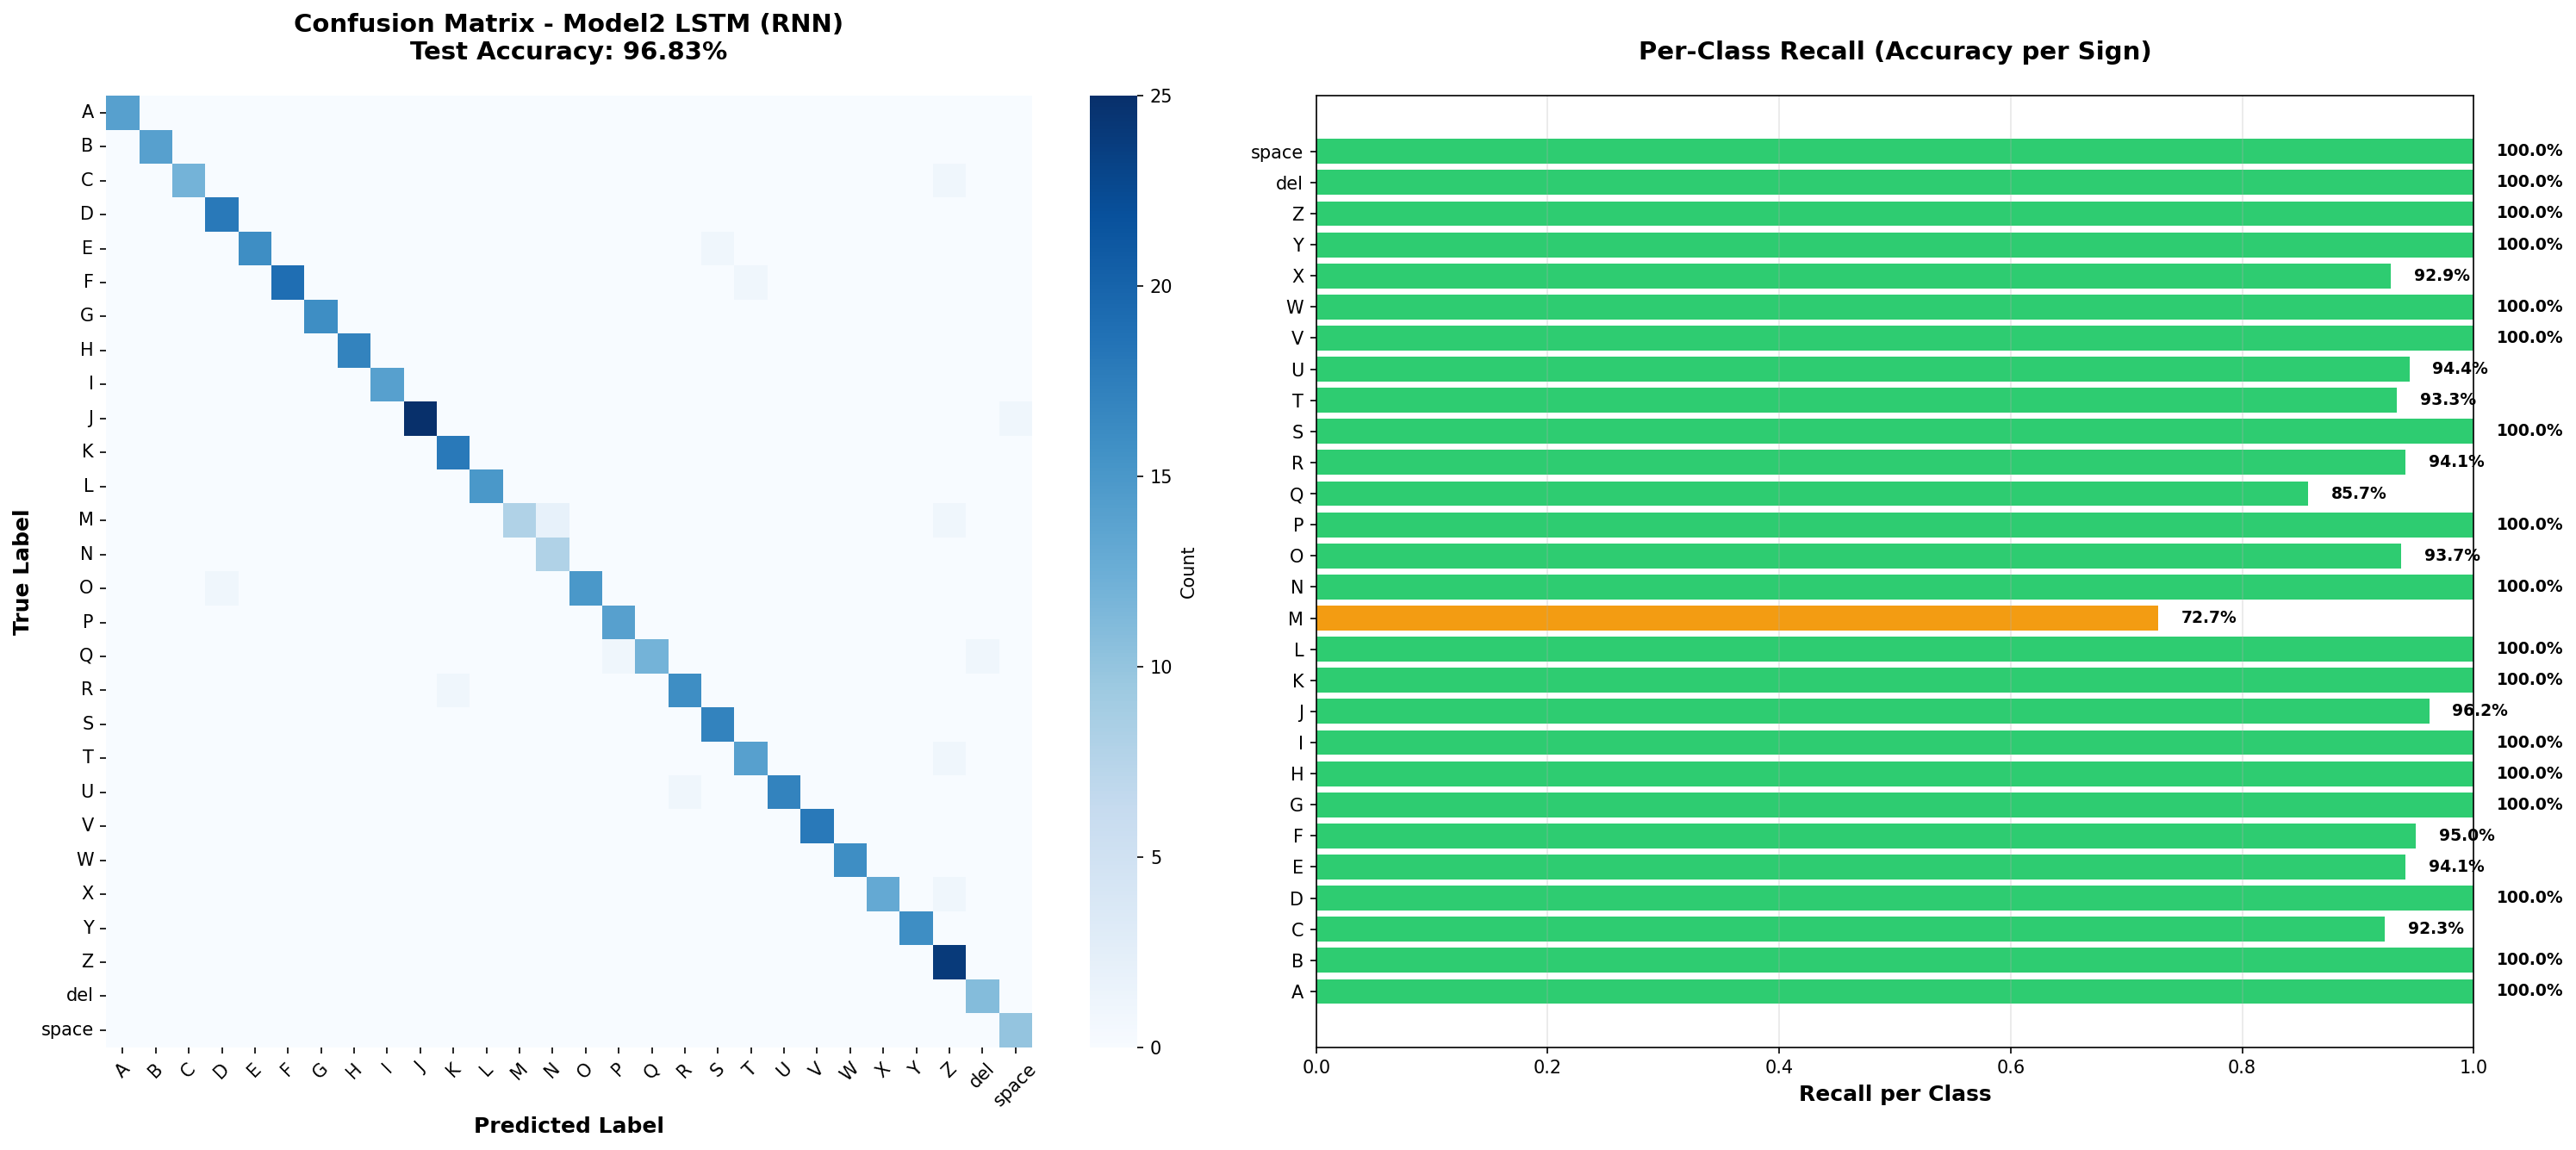

Saved: model2_confusion_matrix_rnn.png


In [28]:
cm = confusion_matrix(y_test, y_pred, labels=labels_all)
recall_per_class = np.diag(cm) / (cm.sum(axis=1) + 1e-9)

fig, axes = plt.subplots(1, 2, figsize=(20, 9), dpi=150)

# Confusion matrix
ax1 = axes[0]
sns.heatmap(
    cm, cmap="Blues", annot=False,
    xticklabels=le.classes_, yticklabels=le.classes_,
    cbar_kws={"label": "Count"}, ax=ax1
)
ax1.set_xlabel("Predicted Label", fontsize=12, fontweight="bold")
ax1.set_ylabel("True Label", fontsize=12, fontweight="bold")
ax1.set_title(f"Confusion Matrix - Model2 {RNN_TYPE.upper()} (RNN)\nTest Accuracy: {acc*100:.2f}%",
              fontsize=14, fontweight="bold", pad=20)
ax1.tick_params(axis="x", rotation=45)

# Per-class recall
ax2 = axes[1]
colors = ['#2ecc71' if x > 0.8 else '#f39c12' if x > 0.6 else '#e74c3c'
          for x in recall_per_class]
ax2.barh(le.classes_, recall_per_class, color=colors)
ax2.set_xlabel("Recall per Class", fontsize=12, fontweight="bold")
ax2.set_title("Per-Class Recall (Accuracy per Sign)", fontsize=14, fontweight="bold", pad=20)
ax2.set_xlim(0, 1)
ax2.grid(axis="x", alpha=0.3)

for i, val in enumerate(recall_per_class):
    ax2.text(val + 0.02, i, f"{val*100:.1f}%", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("model2_confusion_matrix_rnn.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: model2_confusion_matrix_rnn.png")

#### 11) SAVE METRICS CSV

In [29]:
metrics_df = pd.DataFrame({
    "Class": le.classes_,
    "Recall": recall_per_class,
    "Total_Samples": cm.sum(axis=1),
    "Correct_Predictions": np.diag(cm)
})
metrics_df["Recall_Percent"] = metrics_df["Recall"] * 100

overall = pd.DataFrame([{
    "Class": "OVERALL",
    "Recall": acc,
    "Total_Samples": int(cm.sum()),
    "Correct_Predictions": int(np.diag(cm).sum()),
    "Recall_Percent": acc * 100
}])

metrics_df = pd.concat([metrics_df, overall], ignore_index=True)
metrics_df.to_csv("model2_rnn_metrics.csv", index=False)
print("Saved: model2_rnn_metrics.csv")

Saved: model2_rnn_metrics.csv


#### 12) SAVE MODEL + LABEL ENCODER

In [30]:
model2.save("model2_rnn_landmarks.keras")
joblib.dump(le, "model2_label_encoder.joblib")
print("Saved model: model2_rnn_landmarks.keras")
print("Saved label encoder: model2_label_encoder.joblib")

Saved model: model2_rnn_landmarks.keras
Saved label encoder: model2_label_encoder.joblib
